# Skill Lab 3 | Evidencia, recuperación y acciones controladas
**Individual · Semana 7 · 5 puntos · Un conjunto común · Entrega en PDF**

Un solo ejercicio con dos caminos: `sin_api` (predeterminado, sin tokens) o `luna_api` (una consulta al Aula). Ambos se evalúan con la misma rúbrica. Usar Luna no da puntos adicionales ni es requisito para obtener la puntuación completa.

## Contexto de negocio
En Distribuidora Cuauhtémoc una captura antigua de la brecha del preventista PREV-017 puede llevar a una decisión equivocada. Además, registrar un caso duplicado o con un identificador inexistente genera trabajo de corrección.

Primero compararás tres paquetes de contexto con datos didácticos precargados. Después observarás cómo un flujo con estado controla cuatro intentos de registrar casos. La bandeja solo es una lista en memoria: no se conecta con la operación de una empresa.

**Relación con el Aprende:** el enrutador propone el siguiente paso; un control independiente revisa existencia, duplicados y conflictos; la bandeja conserva el estado; la ruta `escalada` reserva la decisión a una persona. Es un flujo pequeño con roles separados, no una sociedad completa de agentes. No hace falta consultar materiales de semanas posteriores.

## Objetivo
1. Comparar tamaño y vigencia de tres paquetes de contexto, distinguiendo datos simulados de mediciones reales.
2. Seguir un flujo condicional y explicar sus cuatro veredictos usando el registro de ejecución.
3. Distinguir la recomendación del enrutador de la autorización para escribir.
4. Explicar la reversibilidad y el costo de corregir dos registros indebidos, declarando tus supuestos.

## Diccionario de datos
Todos utilizan `skill_lab3_datos.json`. No necesitas solicitar ni introducir un código personal.

| Campo | Significado |
|---|---|
| `dias_captura` | Antigüedad simulada de la captura usada por el paquete sin fechas. |
| `tokens_curado` | Tamaño didáctico precargado, no consumo real de Luna. |
| `tienda`, `producto` | Identificadores del caso común. |

El archivo no contiene documentos empresariales ni evidencia para demostrar que un modelo recuperó información. La comparación de paquetes no ejecuta búsquedas ni mide la calidad real de un modelo.

## Cómo trabajar este notebook
1. Descomprime `Skill_Lab_3.zip`. Abre `Skill_Lab_3.ipynb` en [Colab](https://colab.research.google.com/) mediante **Archivo → Subir notebook**. Guarda una copia propia si quieres conservarla.
2. En el panel **Archivos** de Colab, sube los otros tres archivos: `skill_lab3_datos.json`, `orquestacion_aula.py` y `exportar_pdf.py`. No hace falta montar Drive. Si se reinicia el entorno, vuelve a subirlos.
3. Ejecuta en orden. Mantén `MODO = "sin_api"` o elige `luna_api` en la celda de configuración. No necesitas realizar ambos caminos.
4. Completa las celdas **DECISIÓN**. El código calcula los cinco resultados; tú explicas por qué se obtuvieron, eliges el paquete y justificas la reversibilidad.
5. Al final, ejecuta las pruebas, revisa los pendientes y genera el PDF bajo demanda. Comprueba el archivo antes de subirlo a Canvas.

**Parte A:** contexto. **Parte B:** flujo y controles. Ambas pertenecen a esta semana. No hay entrega adicional del notebook ni una liga editable como sustituto del PDF.

### Qué se evalúa
| Criterio vigente | Evidencia que debes incluir |
|---|---|
| Resultados técnicos: 60/100 (3 de los 5 puntos) | Cinco valores del resumen, cada uno con una explicación breve que identifique su dato o regla de origen. |
| Interpretación: 40/100 (2 de los 5 puntos) | Elección del paquete con evidencia numérica; clasificación y costo de corregir duplicado y tienda inexistente, con supuestos claros. |
| Declaración de IA: requisito, 0 puntos | Herramientas usadas, propósito y lo que verificaste; o indica que no utilizaste IA. Usar Luna también debe declararse. |

Las conclusiones sintetizan estas mismas evidencias: no agregan un criterio ni puntos nuevos. No se califica que Luna coincida siempre con las reglas. Si falla, documenta lo ocurrido y completa el camino local. Una discrepancia del modelo no sustituye tu razonamiento ni lo invalida por sí sola.

Los números y reglas del conjunto común están dados; no se pide diseñar otros parámetros ni implementar una empresa real. Una alternativa argumentada no equivale automáticamente a un error. Si propones otra clasificación de reversibilidad, explica qué supusiste y distingue lo implementado de lo hipotético.

# Librerías

- **pandas** — los paquetes se comparan en tabla, no de memoria.
- **matplotlib** — el tamaño de cada paquete se ve; la trampa, también.
- **De la biblioteca estándar: `dataclasses` y `enum`** — el paquete de contexto y el resultado de cada acción serán estructuras **tipadas**: un `ResultadoAccion` solo puede ser uno de cuatro valores. La aduana no devuelve prosa: devuelve un veredicto de un conjunto cerrado — la misma disciplina que el catálogo de herramientas exige en tu proyecto.

### Dos caminos, el mismo alcance
**Sin API:** el enrutador aplica reglas locales y no consume tokens.

**Con Luna:** usa la clave personal recibida por mensaje privado en Canvas. Consulta tu saldo en [el portal del alumno](https://aula.gluber.link/alumno) y las instrucciones en [la guía del Aula](https://aula.gluber.link/wiki). No solicites una clave de Azure ni uses la de un compañero.

La dirección vigente del Aula es `https://aula.gluber.link`; este notebook usa su ruta `/v1/chat/completions` y el modelo `gpt-5.6-luna`, como el material anterior. Si tu mensaje privado indica una dirección diferente, confirma con el equipo docente antes de enviar una clave.

La clave se solicita en un campo oculto, nunca en una celda de texto. Se envían solo cuatro casos sintéticos (identificadores 1 a 4 y condiciones verdaderas/falsas), no datos personales, trabajos ni documentos. Una consulta puede consumir parte de tu cuota. Las repeticiones idénticas reutilizan la respuesta en la misma sesión; reiniciar el entorno pierde esa memoria. No reinicies para forzar consultas.

Si falta saldo, la clave falla o la respuesta no cumple el formato, no hay reintentos automáticos. Continúa `sin_api`; no necesitas comprar tokens. El modo real no ejecuta acciones empresariales ni escribe por orden del modelo.

In [1]:
MODO = "luna_api"  # sin_api | luna_api
AUTORIZAR_CONSULTA = True  # Solo cambia a True si eliges luna_api y aceptas usar tu cuota.
print("Modalidad seleccionada:", MODO)

Modalidad seleccionada: luna_api


In [2]:
from __future__ import annotations
import json, os, re, io
from dataclasses import dataclass, field
from enum import Enum
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_colwidth", None)
print("Librerías disponibles. No se ha consultado ningún modelo.")

Librerías disponibles. No se ha consultado ningún modelo.


# Carga del conjunto común
La carga valida tipos y nombres. No modifiques los datos o el catálogo para hacer que un control pase. Los identificadores solo pertenecen a esta simulación.

In [3]:
RUTA_DATOS = "skill_lab3_datos.json"
def cargar_datos(ruta=RUTA_DATOS):
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"Falta {ruta}. Descomprime el ZIP y sube el JSON al panel Archivos de Colab.")
    with open(ruta, encoding="utf-8") as f:
        d=json.load(f)
    if not isinstance(d,dict) or set(d)!={"dias_captura","tokens_curado","tienda","producto"}:
        raise ValueError("El archivo común no tiene los cuatro campos esperados.")
    for campo,minimo in (("dias_captura",0),("tokens_curado",1)):
        if type(d[campo]) is not int or d[campo]<minimo:
            raise ValueError(f"{campo} debe ser entero mayor o igual a {minimo}.")
    for campo,patron in (("tienda",r"T[0-9]{4}"),("producto",r"P[0-9]{3}")):
        if not isinstance(d[campo],str) or not re.fullmatch(patron,d[campo]):
            raise ValueError(f"Identificador no válido: {campo}.")
    return d
v=cargar_datos()
TIENDAS_VALIDAS=frozenset({v["tienda"],"T0002"})
PRODUCTOS_VALIDOS=frozenset({v["producto"],"P002"})
print("Conjunto común cargado:",v)
print("Catálogo didáctico local; no se verifica contra una empresa real.")

Conjunto común cargado: {'dias_captura': 32, 'tokens_curado': 1018, 'tienda': 'T0030', 'producto': 'P012'}
Catálogo didáctico local; no se verifica contra una empresa real.


## Sección A — La mesa de contexto

### El concepto

La ventana del modelo es una **mesa**: caben pocos papeles, y el modelo trabajará con lo que le pongas enfrente. Armar el paquete de contexto es decidir qué papeles entran, y la regla de oro del módulo tiene cuatro verbos: **seleccionar, comprimir, aislar, citar** — con la vigencia como condición de entrada.

```
  TRES PAQUETES, LA MISMA PREGUNTA DEL CASO
                 +--------------------------------------+
  GENEROSO   --> | 24 fragmentos · 6,800 tokens         | --> evidencia DILUIDA (no la usa)
                 +--------------------------------------+
  SIN FECHAS --> |  6 fragmentos · 1,500 tokens         | --> usa evidencia... CADUCA
                 +--------------------------------------+
  CURADO     --> |  5 fragmentos · fechados y citados   | --> evidencia DECISIVA y vigente
                 +--------------------------------------+
  La mesa no se gana por tamaño: se gana por selección, vigencia y cita.
```

El paquete de en medio es la trampa de este laboratorio: es chico, barato y **responde con seguridad**. Solo la fecha de su evidencia lo delata.

### La técnica: paquetes tipados

Cada paquete declara las propiedades que compararemos. Las anotaciones de tipo no validan por sí solas: añadimos comprobaciones explícitas para texto, cantidades y antigüedad. Estos controles verifican estructura, no veracidad. La antigüedad del ejemplo sin fechas la aporta la simulación para el análisis; no fue extraída de documentos por el notebook.

,fragmentos,tokens,uso_evidencia,dias_evidencia
nombre,,,,
generoso,24,6800,NO: la captura decisiva quedó diluida,NaN
sin_fechas,6,1500,"SÍ, pero con evidencia caduca",32.0
curado,5,1018,"SÍ: evidencia decisiva, fechada y citada",2.0


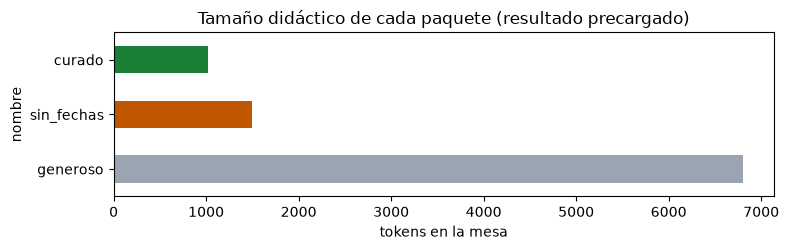

En el escenario simulado, el paquete sin fechas usa una captura de 32 días de la brecha del preventista PREV-017.


In [4]:
@dataclass(frozen=True)
class PaqueteContexto:
    """Propiedades y resultado didáctico precargado; no desempeño medido aquí."""
    nombre: str
    fragmentos: int
    tokens: int
    uso_evidencia: str        # qué hizo con la evidencia decisiva
    dias_evidencia: int | None  # antigüedad de la evidencia usada (None = no la usó)


    def __post_init__(self):
        for campo in ("nombre", "uso_evidencia"):
            if not isinstance(getattr(self, campo), str) or not getattr(self, campo).strip():
                raise ValueError(f"{campo} debe ser texto no vacío.")
        for campo in ("fragmentos", "tokens"):
            if type(getattr(self, campo)) is not int or getattr(self, campo) <= 0:
                raise ValueError(f"{campo} debe ser entero positivo, no booleano.")
        if self.dias_evidencia is not None and (type(self.dias_evidencia) is not int or self.dias_evidencia < 0):
            raise ValueError("dias_evidencia debe ser entero no negativo o None.")

PAQUETES: list[PaqueteContexto] = [
    PaqueteContexto("generoso", 24, 6_800,
                    "NO: la captura decisiva quedó diluida", None),
    PaqueteContexto("sin_fechas", 6, 1_500,
                    "SÍ, pero con evidencia caduca", v["dias_captura"]),
    PaqueteContexto("curado", 5, v["tokens_curado"],
                    "SÍ: evidencia decisiva, fechada y citada", 2),
]

df_paquetes = pd.DataFrame([p.__dict__ for p in PAQUETES]).set_index("nombre")
display(df_paquetes)

colores = {"generoso": "#9aa5b1", "sin_fechas": "#c05600", "curado": "#1a7f37"}
ax = df_paquetes["tokens"].plot.barh(
    figsize=(8, 2.6), color=[colores[n] for n in df_paquetes.index])
ax.set_title("Tamaño didáctico de cada paquete (resultado precargado)")
ax.set_xlabel("tokens en la mesa")
plt.tight_layout()
plt.show()

print(f"En el escenario simulado, el paquete sin fechas usa una captura de "
      f"{v['dias_captura']} días de la brecha del preventista PREV-017.")

**Qué deberías ver:** la tabla de los tres paquetes y una gráfica donde el generoso (gris) es enorme y no usó la evidencia; el sin fechas (naranja) es chico pero su evidencia tiene `dias_captura` días; y el curado (verde) es igual de chico con evidencia de 2 días, fechada y citada.

### El método: la vigencia no es opcional

Los conteos del ejemplo permiten comparar tamaños, no demostrar aciertos, costo real ni calidad de respuestas. El escenario sin fechas ilustra el riesgo de usar evidencia caduca. La antigüedad está precargada para que puedas identificarlo: en un sistema real habría que extraer y validar las fechas de las fuentes.

Con tus números enfrente, decide y explica los límites de esta comparación.

In [5]:
# DECISIÓN | ¿Qué paquete elegirías en este caso y por qué?
# Cita al menos un número de la tabla; explica también qué limitaciones tiene esta simulación.
PAQUETE_ELEGIDO = "curado"        # generoso | sin_fechas | curado
POR_QUE = """Si elegimos el paquete generoso, nos arriesgamos a consumir más recursos de los necesarios. Además, debido a la cantidad de datos que se manejan, se podría perder detalle o incluso generar alucinaciones en la respuesta.
Por otro lado, si se usa el paquete sin fechas, corremos el riesgo de llegar a conclusiones incorrectas por falta de contexto temporal, ya que contiene información de 32 días mezclados.
Por eso, el paquete curado resulta ser la mejor opción en este caso: contiene datos de una ventana de tiempo bien definida (2 días) y es confiable porque incluye citas verificables."""

def texto_completo(valor):
    return (isinstance(valor, str) and bool(valor.strip())
            and not re.search(r"_{3,}", valor)
            and valor.strip().casefold() not in {"pendiente", "por completar", "n/a"}
            and any(c.isalpha() for c in valor))

def validar_eleccion(paquete, motivo):
    pendientes = []
    if not isinstance(paquete, str) or paquete not in {p.nombre for p in PAQUETES}:
        pendientes.append("Elige generoso, sin_fechas o curado.")
    if not texto_completo(motivo):
        pendientes.append("Completa POR_QUE con tu justificación.")
    elif not re.search(r"[0-9]", motivo):
        pendientes.append("Cita al menos un número de la tabla en POR_QUE.")
    return pendientes

problemas_eleccion = validar_eleccion(PAQUETE_ELEGIDO, POR_QUE)
for p in problemas_eleccion:
    print(p)
if not problemas_eleccion:
    print("Formato registrado. El profesor comprobará la evidencia y el razonamiento en tu PDF.")

Formato registrado. El profesor comprobará la evidencia y el razonamiento en tu PDF.


## Sección B — La aduana de acciones
Las precondiciones son comprobaciones anteriores a una escritura. En este ejercicio forman un punto de control con tres preguntas, en este orden:

1. ¿Existen tienda y producto en el catálogo? Si no, `rechazada_precondicion`.
2. ¿Ya está registrado ese par? Si sí, `rechazada_duplicado`.
3. ¿Hay conflicto con una promoción? Si sí, `escalada`, sin escribir.
4. Si pasa las tres comprobaciones, `aceptada` y se añade una entrada local.

`conflicto` es un dato simulado, no un detector de promociones. Escalar reserva la decisión a una persona, pero aquí no envía un aviso ni espera una respuesta real. No se implementa un flujo humano completo.

**Del Aprende al código:** el enrutador propone, el control decide con reglas y la bandeja conserva el estado. La propuesta del modelo nunca omite las precondiciones. Llamamos **registro de ejecución** a la secuencia de casos, decisiones y estado antes/después; no necesitas interpretar una “traza” sin explicación.

### La técnica: veredictos de conjunto cerrado

La aduana no devuelve prosa: devuelve un `ResultadoAccion` — uno de cuatro valores posibles, y nada más. Quien consuma este resultado (un orquestador, un log, tu verificador) puede confiar en el tipo. Es el contrato de herramienta del catálogo de tu proyecto, en miniatura.

In [6]:
class ResultadoAccion(str, Enum):
    """Los cuatro veredictos posibles de la aduana. Conjunto cerrado."""
    ACEPTADA = "aceptada"
    RECHAZADA_PRECONDICION = "rechazada_precondicion"
    RECHAZADA_DUPLICADO = "rechazada_duplicado"
    ESCALADA = "escalada"


@dataclass
class Bandeja:
    """Sandbox de la bandeja de casos con su aduana de precondiciones.

    Con `precondiciones=False` en una llamada, la aduana se apaga para esa
    llamada: es el interruptor que la celda de ruptura usa para mostrarte
    qué entraría sin control.
    """
    entradas: list[tuple[str, str, bool]] = field(default_factory=list, init=False)
    tiendas_validas: frozenset = field(default_factory=lambda: TIENDAS_VALIDAS)
    productos_validos: frozenset = field(default_factory=lambda: PRODUCTOS_VALIDOS)

    def __post_init__(self):
        for campo in ("tiendas_validas", "productos_validos"):
            catalogo = getattr(self, campo)
            if not isinstance(catalogo, (set, frozenset)) or not catalogo or not all(isinstance(x, str) and x.strip() for x in catalogo):
                raise ValueError(f"{campo} debe ser un conjunto no vacío de identificadores.")
            setattr(self, campo, frozenset(catalogo))

    TIENDA_INEXISTENTE = "T9999"

    def escribir_caso(self, tienda: str, producto: str, *,
                      conflicto: bool = False,
                      precondiciones: bool = True) -> ResultadoAccion:
        """Intenta escribir un caso; devuelve el veredicto de la aduana."""
        # El interruptor solo omite reglas de negocio en la demostración local.
        # Los tipos siguen siendo obligatorios, incluso durante la ruptura.
        if (not isinstance(tienda, str) or not isinstance(producto, str)
                or not tienda.strip() or not producto.strip()
                or type(conflicto) is not bool or type(precondiciones) is not bool):
            return ResultadoAccion.RECHAZADA_PRECONDICION
        if precondiciones:
            if tienda not in self.tiendas_validas or producto not in self.productos_validos:
                return ResultadoAccion.RECHAZADA_PRECONDICION
            if any(e[:2] == (tienda, producto) for e in self.entradas):
                return ResultadoAccion.RECHAZADA_DUPLICADO
            if conflicto:
                return ResultadoAccion.ESCALADA
        self.entradas.append((tienda, producto, conflicto))
        return ResultadoAccion.ACEPTADA

### La ruta propuesta y el control independiente
El enrutador recibe las condiciones de cuatro casos en orden. En `sin_api` aplica reglas; en `luna_api` una consulta pide las cuatro propuestas. Después la misma clase `Bandeja` comprueba cada intento con los datos originales, no con los permisos que sugiera el modelo.

Una propuesta estructurada no equivale a una autorización. Si difiere del control, el registro conserva ambos valores para analizarlos. Es deliberadamente un caso sencillo: permite comparar el costo de usar un modelo donde las reglas ya bastan.

In [7]:
from orquestacion_aula import proponer_rutas
INTENTOS = [(v["tienda"],v["producto"],False),
            ("T9999",v["producto"],False),
            (v["tienda"],v["producto"],False),
            ("T0002","P002",True)]
NOMBRES = ["Caso válido","Tienda inexistente","Duplicado","Conflicto con promoción"]
# Preparación de las condiciones observables. No depende de las propuestas de Luna.
estado_previo=Bandeja()
CASOS=[]
for i,(tienda,producto,conflicto) in enumerate(INTENTOS,1):
    CASOS.append({"id":i,"tienda_valida":tienda in TIENDAS_VALIDAS,
                  "producto_valido":producto in PRODUCTOS_VALIDOS,
                  "duplicado":any(e[:2]==(tienda,producto) for e in estado_previo.entradas),
                  "conflicto":conflicto})
    estado_previo.escribir_caso(tienda,producto,conflicto=conflicto)

def obtener_propuestas():
    if MODO == "sin_api":
        return proponer_rutas(CASOS,modo=MODO)
    if MODO != "luna_api":
        raise ValueError("Elige sin_api o luna_api.")
    if AUTORIZAR_CONSULTA is not True:
        raise ValueError("La consulta real no está autorizada. Usa sin_api o cambia AUTORIZAR_CONSULTA a True.")
    from getpass import getpass
    clave=getpass("Tu API key personal del Aula (oculta): ").strip()
    try:
        return proponer_rutas(CASOS,modo=MODO,clave=clave)
    finally:
        clave=None  # No se guarda ni se incorpora al PDF.

INCIDENTE_API=""
try:
    PROPUESTAS,META=obtener_propuestas()
except (ValueError,RuntimeError) as error:
    # Solo mensajes controlados del adaptador. Nunca imprimir cuerpo HTTP o credenciales.
    INCIDENTE_API=str(error)
    print(INCIDENTE_API)
    print("Se completa esta ejecución con reglas locales; no se presenta como respuesta real de Luna.")
    PROPUESTAS,META=proponer_rutas(CASOS,modo="sin_api")
    META["modo_solicitado"]=MODO

bandeja=Bandeja()
REGISTRO=[]
veredictos=[]
for i,((tienda,producto,conflicto),propuesta) in enumerate(zip(INTENTOS,PROPUESTAS),1):
    antes=len(bandeja.entradas)
    veredicto=bandeja.escribir_caso(tienda,producto,conflicto=conflicto)
    veredictos.append(veredicto)
    REGISTRO.append({"id":i,"caso":NOMBRES[i-1],"propuesta":propuesta["ruta"],
                     "motivo":propuesta["motivo"],"veredicto":veredicto.value,
                     "antes":antes,"despues":len(bandeja.entradas),
                     "coincide":propuesta["ruta"]==veredicto.value})
r1,r2,r3,r4=veredictos
resultados=pd.DataFrame(REGISTRO)
display(resultados)
print("Bandeja final:",len(bandeja.entradas),"entrada(s). Modalidad realizada:",META["modo"])
print("Consumo informado por el servicio:",META)
print("No confundir estos tokens reales con los tamaños simulados de la sección A.")

,id,caso,propuesta,motivo,veredicto,antes,despues,coincide
0,1,Caso válido,aceptada,La tienda y el producto son válidos y no hay duplicado ni conflicto.,aceptada,0,1,True
1,2,Tienda inexistente,rechazada_precondicion,La tienda no es válida.,rechazada_precondicion,1,1,True
2,3,Duplicado,rechazada_duplicado,La propuesta está duplicada.,rechazada_duplicado,1,1,True
3,4,Conflicto con promoción,escalada,Existe un conflicto que requiere escalamiento.,escalada,1,1,True


Bandeja final: 1 entrada(s). Modalidad realizada: luna_api
Consumo informado por el servicio: {'modo': 'luna_api', 'origen': 'Luna por Aula Gateway', 'modelo': 'gpt-5.6-luna', 'llamadas': 1, 'tokens_entrada': 261, 'tokens_salida': 167, 'reutilizada': False}
No confundir estos tokens reales con los tamaños simulados de la sección A.


**Qué deberías ver:** cuatro veredictos distintos — `aceptada`, `rechazada_precondicion`, `rechazada_duplicado` y `escalada` — y UNA sola entrada en la bandeja. Cada rechazo es una decisión de diseño trabajando, no un error del sistema. El duplicado se rechaza sin modificar el caso previo. Una sustitución o compensación necesitaría una regla adicional, que no se implementa en este laboratorio.

### La celda de ruptura: la aduana apagada

Las mismas tres primeras llamadas, sin precondiciones. Cuenta qué entra — y ponle precio a cada entrada indebida con la pregunta del contrato: ¿qué costaría corregirla?

In [8]:
bandeja_sin_aduana = Bandeja()
for args in [(v["tienda"], v["producto"]),
             ("T9999", v["producto"]),
             (v["tienda"], v["producto"])]:
    bandeja_sin_aduana.escribir_caso(*args, precondiciones=False)

indebidas = len(bandeja_sin_aduana.entradas) - 1  # la primera era legítima
print(f"Sin aduana, la bandeja admitió {len(bandeja_sin_aduana.entradas)} entradas; "
      f"{indebidas} de ellas eran indebidas (la tienda fantasma y el duplicado).")

Sin aduana, la bandeja admitió 3 entradas; 2 de ellas eran indebidas (la tienda fantasma y el duplicado).


### Cómo justificar la reversibilidad
Para cada entrada indebida, indica una clase y explica el costo de corregirla. Distingue:

- **Lo ejecutado:** una lista local que se puede reconstruir, sin avisos ni pedidos externos.
- **Tu supuesto de operación real:** por ejemplo, si alguien ya usó el registro para decidir o si solo quedó almacenado. No afirmes que eso ocurrió en este notebook.

No hay una única clase universal para un duplicado: depende de sus efectos. Se evalúa la coherencia entre clase, supuesto y corrección propuesta. No necesitas inventar una cantidad monetaria; puedes explicar tiempo, conciliación o consecuencias que no se pueden revertir.

In [9]:
# DECISIÓN | Clasifica cada entrada indebida por su clase de reversibilidad
# Valores válidos: "reversible" · "reversible_con_costo" · "irreversible"
# y en una frase: qué costaría corregirla en la operación real.
CLASES_VALIDAS = {"reversible", "reversible_con_costo", "irreversible"}

REVERSIBILIDAD: dict[str, dict[str, str]] = {
    "duplicado": {"clase": "reversible_con_costo", "costo_de_corregir": "Podrían generarse órdenes de producto duplicadas, lo que supondría una pérdida de producto ya registrado."},
    "tienda_inexistente": {"clase": "reversible", "costo_de_corregir": "Una tienda inexistente implicaría que habría que crearla o corregirla en el sistema. Como no existe realmente, no debería haberse registrado ninguna transacción asociada a ella."},
}


def validar_reversibilidad(registro):
    """Control formal; no califica la elección ni el costo argumentado."""
    if not isinstance(registro, dict):
        return ["REVERSIBILIDAD debe ser un diccionario."]
    esperadas = ("duplicado", "tienda_inexistente")
    pendientes = [f"falta {k}" for k in esperadas if k not in registro]
    for entrada, datos in registro.items():
        if entrada not in esperadas:
            pendientes.append(f"{entrada!r}: entrada no esperada.")
        if not isinstance(datos, dict):
            pendientes.append(f"{entrada}: se esperan clase y costo_de_corregir.")
            continue
        clase = datos.get("clase")
        if not isinstance(clase, str) or clase not in CLASES_VALIDAS:
            pendientes.append(f"{entrada}: clase inválida.")
        if not texto_completo(datos.get("costo_de_corregir")):
            pendientes.append(f"{entrada}: completa el costo de corregir.")
    return pendientes


problemas = validar_reversibilidad(REVERSIBILIDAD)
if problemas:
    print("Antes de seguir:")
    for p in problemas:
        print("   -", p)
else:
    display(pd.DataFrame(REVERSIBILIDAD).T)
    print("Formato registrado; incluye clasificación y justificación en el PDF para revisión docente.")

,clase,costo_de_corregir
duplicado,reversible_con_costo,"Podrían generarse órdenes de producto duplicadas, lo que supondría una pérdida de producto ya registrado."
tienda_inexistente,reversible,"Una tienda inexistente implicaría que habría que crearla o corregirla en el sistema. Como no existe realmente, no debería haberse registrado ninguna transacción asociada a ella."


Formato registrado; incluye clasificación y justificación en el PDF para revisión docente.


# Resumen para tu PDF de resultados
Explica los cinco valores del resumen con una o dos frases por valor. Para los dos tamaños/antigüedades identifica de dónde sale el dato; para los veredictos identifica la regla; para las entradas indebidas explica la comparación con y sin controles. No se pide copiar otra vez todo el código.

La elección del paquete y la reversibilidad se valoran en interpretación. No se debe descontar dos veces por la misma deficiencia sin identificar efectos distintos. La evidencia difícil de leer se distingue de evidencia ausente; por eso el exportador conserva texto completo y registros, no capturas pequeñas.

In [10]:
# DECISIÓN | Justificaciones de los cinco resultados (no las completa el modelo).
JUSTIFICACIONES = {
    "1": "El paquete curado contiene una cantidad de tokens similar a la del paquete sin fechas, a pesar de cubrir una ventana temporal más corta. Esto se debe a que incluye citas verificables y fechas concretas.",
    "2": "El paquete sin fechas usa una captura de 32 días de antigüedad y tiene una cantidad de tokens similar a la del paquete curado. Sin embargo, carece de fechas concretas, por lo que la información es menos precisa.",
    "3": "Cuando se detecta que la tienda que se intenta consultar no existe, el proceso se interrumpe y es necesario corregir la información antes de continuar. No se asume que haya sido un error de entrada ni un intento malicioso.",
    "4": "Al detectar un conflicto con una promoción existente, el proceso se escala para que el equipo humano correspondiente verifique si la promoción es válida.",
    "5": "Al retirar las verificaciones de precondiciones, el sistema deja de validar ciertas condiciones, lo cual puede llevar a errores o inconsistencias en la operación real. En este caso, al no existir un control para tiendas inexistentes, se registran acciones para una tienda fantasma, lo cual es un error de seguridad. Por otro lado, al no existir una verificación de duplicados, se pueden generar registros duplicados que afectan la integridad de los datos.",
}
# DECISIÓN | Herramientas usadas, propósito y verificaciones propias; o declara que no usaste IA.
DECLARACION_IA = "Se usó IA para corregir la puntuación y la ortografía de las justificaciones."
NOMBRE_ALUMNO = "David Felipe Hernandez Chiapa"  # Nombre para tu reporte. No se envía al modelo.
MATRICULA = "A01797374"  # Solo para el nombre de tu PDF; no se envía al modelo.

RESUMEN = [
    ("Tokens didácticos del paquete curado", v["tokens_curado"]),
    ("Días de la captura sin fechas", v["dias_captura"]),
    ("Veredicto de la llamada 2", r2.value),
    ("Veredicto de la llamada 4", r4.value),
    ("Entradas indebidas sin precondiciones", indebidas),
]
for i, (nombre, valor) in enumerate(RESUMEN, 1):
    print(f"{i}. {nombre}: {valor}\nExplicación: {JUSTIFICACIONES.get(str(i),'')}\n")
print("Elección:", PAQUETE_ELEGIDO, "\n", POR_QUE)
for nombre, detalle in REVERSIBILIDAD.items():
    print(nombre, detalle["clase"], "\n", detalle["costo_de_corregir"], "\n")

1. Tokens didácticos del paquete curado: 1018
Explicación: El paquete curado contiene una cantidad de tokens similar a la del paquete sin fechas, a pesar de cubrir una ventana temporal más corta. Esto se debe a que incluye citas verificables y fechas concretas.

2. Días de la captura sin fechas: 32
Explicación: El paquete sin fechas usa una captura de 32 días de antigüedad y tiene una cantidad de tokens similar a la del paquete curado. Sin embargo, carece de fechas concretas, por lo que la información es menos precisa.

3. Veredicto de la llamada 2: rechazada_precondicion
Explicación: Cuando se detecta que la tienda que se intenta consultar no existe, el proceso se interrumpe y es necesario corregir la información antes de continuar. No se asume que haya sido un error de entrada ni un intento malicioso.

4. Veredicto de la llamada 4: escalada
Explicación: Al detectar un conflicto con una promoción existente, el proceso se escala para que el equipo humano correspondiente verifique si la

## Pruebas del instrumento
Comprueban datos y comportamiento del código. No califican la calidad de tus explicaciones. No utilizan tokens. Los cuatro resultados deben mantenerse aunque la propuesta del enrutador sea equivocada.

In [11]:
def pruebas_del_notebook():
    assert cargar_datos()==v
    b=Bandeja()
    obtenido=[b.escribir_caso(t,p,conflicto=c).value for t,p,c in INTENTOS]
    assert obtenido==["aceptada","rechazada_precondicion","rechazada_duplicado","escalada"]
    assert len(b.entradas)==1
    assert indebidas==2
    assert [r["despues"] for r in REGISTRO]==[1,1,1,1]
    assert not Bandeja().escribir_caso("T8888",v["producto"])==ResultadoAccion.ACEPTADA
    assert Bandeja().escribir_caso(v["tienda"],"P999")==ResultadoAccion.RECHAZADA_PRECONDICION
    assert Bandeja().escribir_caso(v["tienda"],v["producto"],precondiciones="False")==ResultadoAccion.RECHAZADA_PRECONDICION
    assert validar_reversibilidad({})
    assert validar_eleccion("curado"," ")
    print("Comprobaciones locales correctas. No equivale a una calificación ni valida toda respuesta del modelo.")
pruebas_del_notebook()

Comprobaciones locales correctas. No equivale a una calificación ni valida toda respuesta del modelo.


# Conclusiones
Escribe dos o tres líneas por punto. Relaciona evidencia, decisiones y límites; no necesitas consultar la próxima semana.

1. **Contexto:** qué regla de selección usarías y qué dato del laboratorio la respalda.
2. **Control:** cuál de las entradas indebidas costaría más corregir, bajo qué supuesto y qué regla la previene.
3. **Orquestación:** quién propuso la ruta, quién autorizó la escritura y por qué se reservó el conflicto a una persona. ¿Aportó algo el modelo o bastaban las reglas en este caso? Responde según el camino que realizaste.

In [ ]:
# DECISIÓN | Síntesis personal; no son tres entregas adicionales.
CONCLUSIONES = {"Contexto": "Usaría el paquete curado, porque ofrece evidencia fechada y citas verificables dentro de una ventana de 2 días. En el laboratorio contiene 1,018 tokens, frente a 1,500 del paquete sin fechas —cuya captura tiene 32 días de antigüedad— y 6,800 del paquete generoso, que no utiliza la evidencia decisiva. Estos datos son didácticos: comparan los paquetes, pero no miden el desempeño real de un modelo.", "Control": "Considero que el duplicado costaría más corregir, suponiendo que la orden duplicada ya hubiera avanzado y fuera necesario cancelar o compensar producto. La tienda inexistente sería más sencilla de corregir si no se registró ninguna transacción asociada. El control de existencia de la tienda previene este último caso, y la verificación de duplicados impide registrar otra vez la misma orden.", "Orquestación": "En el camino con Luna que ejecuté, el modelo propuso las rutas mediante una consulta; no autorizó ninguna escritura. La bandeja y sus reglas independientes validaron las precondiciones y decidieron el resultado. El conflicto con la promoción se reservó para una persona porque requería revisión humana. Luna aportó propuestas, pero para obtener estos veredictos bastaban las reglas del flujo: ellas verificaban las condiciones y controlaban la escritura."}


def pendientes_entrega():
    p = validar_eleccion(PAQUETE_ELEGIDO, POR_QUE) + validar_reversibilidad(
        REVERSIBILIDAD
    )
    for i in range(1, 6):
        if not texto_completo(JUSTIFICACIONES.get(str(i))):
            p.append(f"Explica el resultado {i}.")
    for nombre in ("Contexto", "Control", "Orquestación"):
        if not texto_completo(CONCLUSIONES.get(nombre)):
            p.append("Completa la conclusión: " + nombre)
    if not texto_completo(DECLARACION_IA):
        p.append("Completa la declaración de IA o de no uso.")
    return p


pendientes = pendientes_entrega()
print(
    "\n".join(pendientes)
    if pendientes
    else "Sin campos pendientes. Revisa la calidad de tus argumentos y el PDF."
)

Completa la conclusión: Contexto
Completa la conclusión: Control
Completa la conclusión: Orquestación


## Generar tu PDF bajo demanda
Esta celda crea un **reporte de evidencias**, no una copia de toda la interfaz de Colab. Incluye los cinco resultados explicados, tabla y gráfica, cuatro registros con estado antes/después, elección del paquete, reversibilidad, conclusiones y declaración de IA. No necesitas imprimir el código completo ni hacer capturas.

1. Completa las celdas DECISIÓN y vuelve a ejecutarlas. Si cambias datos o código, ejecuta de nuevo el flujo desde la carga; no mezcles resultados de ejecuciones distintas.
2. Cambia `GENERAR_PDF` a `True` y ejecuta esta última celda. No vuelve a llamar a Luna. La primera vez puede instalar únicamente `reportlab` desde PyPI para construir el documento; no instala LaTeX ni solicita acceso a Drive.
3. Si hay pendientes, el PDF se marca BORRADOR. No entregues esa versión. Si todo está completo, descarga el archivo que se muestra. En Colab se intenta la descarga; si no inicia, usa el panel Archivos.
4. Abre el PDF, revisa todas sus páginas, confirma que aparezcan tus justificaciones completas y tu declaración de IA. Comprueba que no pegaste claves. Súbelo como `SkillLab3_tuMatricula.pdf` a esta actividad en Canvas. No se entrega una liga editable.

La exportación no inventa respuestas ni certifica una calificación. El notebook se conserva como respaldo personal. Puedes preparar el mismo contenido en otro editor si lo prefieres; no hay puntos por usar este exportador. Si no se puede instalar la dependencia, guarda tus respuestas y consulta al equipo docente; no cambies protecciones del navegador.

In [14]:
# Ejecuta esta celda solo cuando quieras generar o actualizar tu PDF.
GENERAR_PDF = True
if GENERAR_PDF:
    try:
        import reportlab
    except ImportError:
        import subprocess,sys
        subprocess.run([sys.executable,"-m","pip","install","reportlab>=4.2,<5"],check=True)
    from exportar_pdf import generar_pdf
    # Crear una gráfica nueva a partir de la tabla de esta ejecución, sin repetir llamadas.
    fig_pdf,ax_pdf=plt.subplots(figsize=(8,2.6))
    ax_pdf.barh([p.nombre for p in PAQUETES],[p.tokens for p in PAQUETES],
                color=["#9aa5b1","#c05600","#1a7f37"])
    ax_pdf.set_xlabel("Tokens didácticos precargados (no consumo de la API)")
    fig_pdf.tight_layout()
    imagen=io.BytesIO()
    fig_pdf.savefig(imagen,format="png",dpi=180)
    plt.close(fig_pdf)
    imagen.seek(0)
    reporte={"alumno":NOMBRE_ALUMNO,"modalidad":META["modo"],"pendientes":pendientes_entrega(),
        "resultados":RESUMEN,"justificaciones":JUSTIFICACIONES,
        "paquetes":[[p.nombre,str(p.fragmentos),str(p.tokens),
                     "No utilizó la evidencia" if p.dias_evidencia is None else str(p.dias_evidencia)+" días"] for p in PAQUETES],
        "paquete":PAQUETE_ELEGIDO,"por_que":POR_QUE,"registro":REGISTRO,
        "consumo":f"entrada: {META.get('tokens_entrada')}; salida: {META.get('tokens_salida')}",
        "incidente":INCIDENTE_API,"reversibilidad":REVERSIBILIDAD,
        "conclusiones":CONCLUSIONES,"declaracion":DECLARACION_IA}
    etiqueta=re.sub(r"[^A-Za-z0-9_-]","",MATRICULA) or "resultados"
    ruta_pdf=generar_pdf(reporte,f"SkillLab3_{etiqueta}.pdf",grafica=imagen)
    print("PDF creado:",ruta_pdf.name)
    print("Revísalo antes de entregarlo. Si generaste varias versiones, el nombre puede llevar un número consecutivo.")
    try:
        from google.colab import files
        files.download(str(ruta_pdf))
    except ImportError:
        print("Fuera de Colab: el archivo está en la carpeta de trabajo.")
    except Exception:
        print("La descarga no inició. Descarga el PDF desde el panel Archivos de Colab.")
else:
    print("Exportación desactivada. Cambia GENERAR_PDF a True cuando tengas lista tu evidencia.")

PDF creado: SkillLab3_A01797374.pdf
Revísalo antes de entregarlo. Si generaste varias versiones, el nombre puede llevar un número consecutivo.
Fuera de Colab: el archivo está en la carpeta de trabajo.
